# Standard 3-Compartment Model Fitting on Simulated Data

This notebook focuses on a single objective:
1. Fit a standard 3-compartment model (intra-neurite, extra-neurite, CSF) and recover fractions plus diffusivities from simulated data.

It also reports identifiability diagnostics so weakly constrained parameter combinations are explicit.

In [9]:
import numpy as np

from dmri_models import (
    Acquisition,
    Ball,
    Component,
    LeastSquaresFitter,
    Model,
    Parameter,
    ParameterSpace,
    Simplex,
    WatsonFOD,
    Zeppelin,
    plot_signal_agreement,
)
from dmri_models.compartments import FODConvolved, Stick

## Standard 3-compartment model fit

This section estimates microstructural parameters for a 3-compartment model:
- intra-neurite stick (Watson dispersed),
- extra-neurite zeppelin (Watson dispersed),
- isotropic CSF ball.

Fitted parameters:
- fractions (`f_in`, `f_ex`, `f_csf`, constrained to sum to one),
- diffusivities (`d_in`, `d_ex_par`, `d_ex_perp`, `d_csf`),
- dispersion/orientation (`kappa`, `theta`, `phi`),
- baseline `S0`.

In [10]:
# Build a mixed LTE/STE protocol (helps identifiability for compartment parameters).
rng_sm = np.random.default_rng(123)

def random_unit_directions(n: int, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    vectors = rng.normal(size=(n, 3))
    vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
    return vectors

n_dirs_per_shell = 40
b_shells = np.array([0.0, 0.7, 1.5, 2.5, 3.5], dtype=float)

bvals_lte = np.repeat(b_shells, n_dirs_per_shell)
beta_lte = np.ones_like(bvals_lte)
grads_lte = random_unit_directions(bvals_lte.size, seed=21)

bvals_ste = np.repeat(b_shells[1:], n_dirs_per_shell)
beta_ste = np.zeros_like(bvals_ste)
grads_ste = random_unit_directions(bvals_ste.size, seed=22)

acq_sm = Acquisition.from_b_values(
    b_values=np.concatenate([bvals_lte, bvals_ste]),
    b_unit="ms/um^2",
    gradients=np.vstack([grads_lte, grads_ste]),
    b_tensor_shape=np.concatenate([beta_lte, beta_ste]),
)

fod_watson = WatsonFOD(
    kappa="kappa",
    theta="theta",
    phi="phi",
    n_theta=24,
    n_phi=48,
)

standard_model = Model(
    components=[
        Component(
            "intra",
            FODConvolved(
                response=Stick(diffusivity="d_in", orientation="axis"),
                fod=fod_watson,
                orientation_parameter="axis",
            ),
            fraction="f_in",
        ),
        Component(
            "extra",
            FODConvolved(
                response=Zeppelin(
                    parallel_diffusivity="d_ex_par",
                    perpendicular_diffusivity="d_ex_perp",
                    orientation="axis",
                ),
                fod=fod_watson,
                orientation_parameter="axis",
            ),
            fraction="f_ex",
        ),
        Component("csf", Ball(diffusivity="d_csf"), fraction="f_csf"),
    ],
    baseline="S0",
)

parameter_space_sm = ParameterSpace(
    parameters=[
        Parameter("S0", 1.0, (0.05, 2.0)),
        Parameter("d_in", 1.8, (0.3, 3.0)),
        Parameter("d_ex_par", 1.3, (0.2, 3.0)),
        Parameter("d_ex_perp", 0.6, (0.0, 2.0)),
        Parameter("d_csf", 3.0, (1.5, 3.5)),
        Parameter("kappa", 1.5, (0.0, 64.0)),
        Parameter("theta", np.pi / 2.0, (0.0, np.pi)),
        Parameter("phi", 0.0, (-np.pi, np.pi)),
    ],
    simplexes=[Simplex(("f_in", "f_ex", "f_csf"), (0.5, 0.35, 0.15))],
)

true_sm = parameter_space_sm.initial_values()
true_sm.update(
    {
        "S0": 1.0,
        "d_in": 1.9,
        "d_ex_par": 1.2,
        "d_ex_perp": 0.5,
        "d_csf": 3.0,
        "kappa": 3.0,
        "theta": 1.0,
        "phi": 0.8,
        "f_in": 0.50,
        "f_ex": 0.35,
        "f_csf": 0.15,
    }
)

signal_true_sm = standard_model.signal(acq_sm, true_sm)
sigma_sm = 0.01
signal_noisy_sm = signal_true_sm + rng_sm.normal(0.0, sigma_sm, size=signal_true_sm.shape)

fitter_sm = LeastSquaresFitter(standard_model, parameter_space_sm)
fit_sm = fitter_sm.fit(
    acq_sm,
    signal_noisy_sm,
    sigma=sigma_sm,
    n_starts=16,
    max_nfev=4000,
    rng=rng_sm,
    initialise_orientation=True,
)

ordered = [
    "S0",
    "f_in",
    "f_ex",
    "f_csf",
    "d_in",
    "d_ex_par",
    "d_ex_perp",
    "d_csf",
    "kappa",
    "theta",
    "phi",
]

print(f"Standard model fit success: {fit_sm.success} | cost={fit_sm.cost:.6f} | nfev={fit_sm.n_evaluations}")
print("\nRecovered parameter table")
print("name       true      fit       abs_err    rel_err_%")
for name in ordered:
    tv = float(true_sm[name])
    fv = float(fit_sm.parameters[name])
    abs_err = fv - tv
    rel_err = 100.0 * abs_err / max(abs(tv), 1e-12)
    print(f"{name:10s} {tv:8.4f}  {fv:8.4f}  {abs_err:+9.4f}  {rel_err:+9.2f}")

# Local identifiability diagnostics around the fitted point.
# Fractions are constrained to sum to one, so we use (f_in, f_ex) as free axes and set f_csf = 1 - f_in - f_ex.
diag_params = ["f_in", "f_ex", "d_in", "d_ex_par", "d_ex_perp", "d_csf", "kappa"]
eps_map = {"f_in": 1e-3, "f_ex": 1e-3, "d_in": 1e-3, "d_ex_par": 1e-3, "d_ex_perp": 1e-3, "d_csf": 1e-3, "kappa": 5e-3}

def _apply_perturb(base: dict[str, float], name: str, delta: float) -> dict[str, float]:
    out = dict(base)
    if name in {"f_in", "f_ex"}:
        out[name] = float(np.clip(out[name] + delta, 1e-6, 1.0 - 1e-6))
        out["f_csf"] = 1.0 - out["f_in"] - out["f_ex"]
        if out["f_csf"] <= 1e-6:
            out["f_csf"] = 1e-6
            remainder = 1.0 - out["f_csf"]
            norm = out["f_in"] + out["f_ex"]
            out["f_in"] = remainder * out["f_in"] / norm
            out["f_ex"] = remainder * out["f_ex"] / norm
    else:
        out[name] = float(np.clip(out[name] + delta, 1e-9, None))
    return out

fit_params = dict(fit_sm.parameters)
jacobian = np.zeros((acq_sm.n_measurements, len(diag_params)), dtype=float)

for col, name in enumerate(diag_params):
    eps = eps_map[name]
    p_plus = _apply_perturb(fit_params, name, +eps)
    p_minus = _apply_perturb(fit_params, name, -eps)
    s_plus = standard_model.signal(acq_sm, p_plus)
    s_minus = standard_model.signal(acq_sm, p_minus)
    jacobian[:, col] = (s_plus - s_minus) / (2.0 * eps)

weighted_jacobian = jacobian / sigma_sm
singular_values_sm = np.linalg.svd(weighted_jacobian, compute_uv=False)
condition_number_sm = float(singular_values_sm[0] / max(singular_values_sm[-1], 1e-12))

fisher = weighted_jacobian.T @ weighted_jacobian
covariance = np.linalg.pinv(fisher)
diag_std = np.sqrt(np.clip(np.diag(covariance), 1e-18, None))
correlation = covariance / np.outer(diag_std, diag_std)
correlation = np.clip(correlation, -1.0, 1.0)

print("\nIdentifiability diagnostics")
print(f"Jacobian shape: {weighted_jacobian.shape}")
print(f"Local condition number (weighted Jacobian): {condition_number_sm:.2e}")

pairs = []
for i in range(len(diag_params)):
    for j in range(i + 1, len(diag_params)):
        pairs.append((abs(correlation[i, j]), diag_params[i], diag_params[j], correlation[i, j]))
pairs.sort(key=lambda item: item[0], reverse=True)

print("Strongest local parameter correlations (absolute):")
for _, left, right, value in pairs[:6]:
    print(f"{left:>8s} vs {right:<8s}: corr={value:+.3f}")

KeyboardInterrupt: 

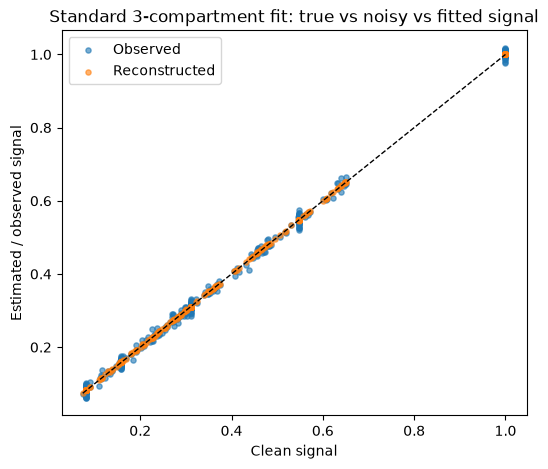

<Axes: title={'center': 'Standard 3-compartment fit: true vs noisy vs fitted signal'}, xlabel='Clean signal', ylabel='Estimated / observed signal'>

In [11]:
plot_signal_agreement(
    clean_signal=signal_true_sm,
    observed_signal=signal_noisy_sm,
    reconstructed_signal=fit_sm.predicted_signal,
    title="Standard 3-compartment fit: true vs noisy vs fitted signal",
)

## Critical Interpretation

- This workflow is a direct nonlinear fit to a forward model; it is not a closed-form invariant inversion.
- Parameter recovery quality depends strongly on acquisition design and SNR. Good signal fit alone does not guarantee unbiased parameters.
- The reported condition number and high-magnitude correlation pairs indicate which parameter combinations are weakly identifiable.
- Orientation angle errors (`theta`, `phi`) should be interpreted with axis symmetry in mind (angles can wrap or flip while representing nearly the same axis).
- For practical studies, reduce degeneracy by fixing known parameters, tightening priors, or improving protocol diversity (for example more shells and mixed encoding).